# 03 — Part 2 baseline and best phase-shared blend

Baseline: independent word TF-IDF + logistic regression per phase. Intermediate model: 25% concatenated-word + 25% separate-field + 50% character model. Best public model: equal blend of that intermediate model and a phase-shared, recency-weighted word model (phase interaction scale 0.35; half-life 6 years).

Stopping reasons and embeddings are excluded from predictors. Saved validation predictions are evaluated here without training or model selection. Success is the positive class; binary F1 uses threshold 0.5. AP means average precision.


In [2]:
from pathlib import Path
import sys, os, json, tempfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'models/selection.json').is_file() and (p/'tools/src').is_dir())
for module_dir in (ROOT/'tools/src', ROOT/'report/scripts'):
    if str(module_dir) not in sys.path:
        sys.path.insert(0, str(module_dir))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir())/'midterm-report-mpl'))
import numpy as np
import pandas as pd
from IPython.display import display, Image, Code
from midterm_evaluation import REASONS, dataset_path
RUN_TRAINING = False  # Explicit opt-in only. Run All uses saved evidence and does not train.
print('Consolidated project | mode: saved evidence | training:', RUN_TRAINING)


In [3]:
from report_analysis import build_report
report=build_report(ROOT)
summary=pd.read_csv(ROOT/'report/analysis/part2_validation_summary.csv')
phase_metrics=pd.read_csv(ROOT/'report/analysis/part2_validation_by_phase.csv')
display(summary)
display(phase_metrics[['model','phase','n_rows','n_positive','n_negative','f1','roc_auc','average_precision','log_loss','tn','fp','fn','tp']])


,model,n_rows,n_unique_trials,log_loss_pooled,log_loss_equal_phase,f1_pooled,roc_auc_pooled,average_precision_pooled,f1_equal_phase,roc_auc_equal_phase,average_precision_equal_phase
0,baseline,1013,901,0.584390,0.583773,0.735418,0.756913,0.798248,0.738570,0.757299,0.801908
1,phase_shared_best,1013,901,0.571313,0.568393,0.738723,0.773749,0.814427,0.740583,0.772197,0.814490


,model,phase,n_rows,n_positive,n_negative,f1,roc_auc,average_precision,log_loss,tn,fp,fn,tp
0,baseline,I,149,85,64,0.779487,0.781985,0.828463,0.596635,30,34,9,76
1,baseline,II,501,236,265,0.623608,0.723585,0.708781,0.608247,192,73,96,140
2,baseline,III,363,240,123,0.812616,0.766328,0.868480,0.546439,43,80,21,219
3,phase_shared_best,I,149,85,64,0.774194,0.796140,0.839969,0.573848,35,29,13,72
4,phase_shared_best,II,501,236,265,0.629712,0.738711,0.725944,0.598292,192,73,94,142
5,phase_shared_best,III,363,240,123,0.817844,0.781741,0.877556,0.533038,45,78,20,220


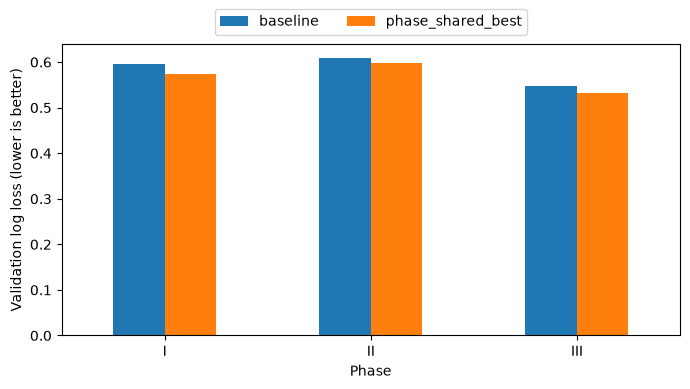

In [4]:
import matplotlib.pyplot as plt
matrix=phase_metrics.pivot(index='phase',columns='model',values='log_loss').reindex(['I','II','III'])
ax=matrix.plot.bar(figsize=(7,4),rot=0)
ax.set_ylabel('Validation log loss (lower is better)'); ax.set_xlabel('Phase')
ax.legend(loc='lower center',bbox_to_anchor=(.5,1.01),ncol=2)
ax.figure.tight_layout(); display(ax.figure); plt.close(ax.figure)


In [5]:
import inspect
from midterm_rank_part2 import phase_design,recency_weights,fit_phase_shared,predict_phase_shared,blend
from midterm_finalization import predict_final_outcomes
from midterm_part2_baseline import fit_phase_baseline
display(Code(inspect.getsource(phase_design)+inspect.getsource(recency_weights)+inspect.getsource(fit_phase_shared),language='python'))
locked=json.loads((ROOT/'models/part2/03_phase_shared/evidence/selection/summary.json').read_text())
display({key:locked[key] for key in ['setting','blend_weight','oof_current_final_loss','oof_candidate_loss',
                                  'temporal_current_final_control_loss','temporal_selected_blend_loss']})


def phase_design(text_matrix, phases: pd.Series, alpha: float):
    """Shared text, optional phase-specific text interactions, and phase intercepts."""
    phase = phases.to_numpy()
    if not np.isin(phase, PHASES).all():
        raise ValueError("Only phases I, II, and III are allowed.")
    indicators = sparse.csr_matrix(np.column_stack([phase == p for p in PHASES]).astype(np.float32))
    blocks = [text_matrix]
    if alpha:
        blocks.extend(text_matrix.multiply((phase == p).astype(np.float32)[:, None]) * alpha for p in PHASES)
    blocks.append(indicators)
    return sparse.hstack(blocks, format="csr", dtype=np.float32)
def recency_weights(frame: pd.DataFrame, half_life: int | None, *, reference_year: int) -> np.ndarray:
    if half_life is None:
        return np.ones(len(frame), dtype=float)
    years = pd.to_numeric(frame.start_year, errors="coerce").to_numpy(dtype=float)
    observed = years[np.isfinite(years)]
    if not len(observed) or np.any(observed > reference_year):
        raise ValueError("Recency weights require known training years not later than the reference year.")
    years = np.where(np.isfinite(years), years, np.median(observed))
    weights = np.exp(-math.log(2) * (reference_year - years) / half_life)
    return weights / weights.mean()  # Same total weight keeps LR regularization comparable.
def fit_phase_shared(train: pd.DataFrame, setting: dict, *, reference_year: int):
    validate_outcome_rows(train)
    vectorizer = TfidfVectorizer(**WORD_PARAMS)
    x_text = vectorizer.fit_transform(build_trial_text(train))
    x = phase_design(x_text, train.phase, setting["alpha"])
    classifier = LogisticRegression(**{**logistic_parameters(42), "C": 1.0, "max_iter": 1000})
    weights = recency_weights(train, setting["half_life"], reference_year=reference_year)
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        classifier.fit(x, train.label.to_numpy(dtype=int), sample_weight=weights)
    if any(issubclass(w.category, ConvergenceWarning) for w in caught) or classifier.n_iter_.max() >= classifier.max_iter:
        raise RuntimeError("Phase-shared LR failed to converge.")
    return {"vectorizer": vectorizer, "classifier": classifier, "setting": dict(setting),
            "reason_features_used": False, "positive_class": 1,
            "fit_row_ids": train.ID.tolist(), "fit_trial_ids": sorted(train.trial_id.unique()),
            "reference_year": reference_year, "vocabulary_size": len(vectorizer.vocabulary_)}

{'setting': {'alpha': 0.35, 'half_life': 6},
 'blend_weight': 0.5,
 'oof_current_final_loss': 0.5964861595292898,
 'oof_candidate_loss': 0.5915460014326781,
 'temporal_current_final_control_loss': 0.58425087205792,
 'temporal_selected_blend_loss': 0.5728800009817229}

## Saved-model inference demonstration

This small test-feature inference confirms that the saved blend matches its submission. It uses no test labels and does not alter files. `python reproduce.py` performs the full submission verification.


In [6]:
import joblib
test=pd.read_csv(dataset_path(ROOT,'part2','test')).iloc[:12].copy()
old_component=joblib.load(ROOT/'models/part2/02_text_blend/model.joblib')
shared_component=joblib.load(ROOT/'models/part2/03_phase_shared/component.joblib')
old_scores=predict_final_outcomes(old_component,test)
shared_scores=predict_phase_shared(shared_component,test)
combined=blend(test,old_scores,shared_scores,.5)
saved=pd.read_csv(ROOT/'models/part2/03_phase_shared/submission.csv').set_index('ID')
np.testing.assert_allclose(combined.p_success,saved.loc[test.ID,'label'],atol=1e-12,rtol=0)
display(combined.head())
print('Saved best blend agrees with submission on these 12 rows.')


,ID,p_success
0,TR11252_III,0.627270
1,TR08672_II,0.572860
2,TR07815_I,0.663723
3,TR08013_I,0.577823
4,TR05100_II,0.578185


## Optional component training (off by default)

This cell shows the exact saved phase-shared component recipe. It fits only outcome training rows and does not tune, submit, or overwrite models. The intermediate text ensemble remains available through the retained training functions in `tools/src/` and its saved configuration. A full historical search is not run by default.


In [7]:
if RUN_TRAINING:
    train=pd.read_csv(dataset_path(ROOT,'part2','train'))
    refit_shared=fit_phase_shared(train,locked['setting'],reference_year=int(train.start_year.max()))
    refit_scores=predict_phase_shared(refit_shared,test)
    np.testing.assert_allclose(refit_scores.p_success,shared_scores.p_success,atol=1e-10,rtol=0)
    print('Selected phase-shared component refit verified; nothing overwritten.')
else:
    print('Optional component training skipped.')
